# Health&Life Analytics - Análise Exploratória de Dados (EDA)
## Impacto do Consumo de Café na Qualidade do Sono e Saúde

**Projeto:** Alura - Cientista de Dados (Nível 1)  
**Etapa:** Parte #1 - Análise Exploratória de Dados

## 1. Configuração do Ambiente e Importação de Bibliotecas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações estéticas globais dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10

## 2. Carregamento do Dataset

In [3]:
url = "https://raw.githubusercontent.com/cleberfmodesto/Checkpoint_Cientista_de_Dados_Nivel_1/main/data/synthetic_coffee_health_10000.csv"
df = pd.read_csv(url)

print("--- Primeiras 5 linhas do dataset ---")
display(df.head())

--- Primeiras 5 linhas do dataset ---


,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


## 3. Inspeção Estrutural dos Dados
Verificação de dimensões, tipos de dados, valores nulos e duplicatas.

In [4]:
print("=" * 50)
print(f"Dimensões do Dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("=" * 50)

print("\n--- Contagem de Nulos por Coluna ---")
nulls = df.isnull().sum()
print(nulls[nulls > 0] if nulls.sum() > 0 else "Nenhum valor nulo encontrado.")

print("\n--- Registros Duplicados ---")
print(f"Total de linhas duplicadas: {df.duplicated().sum()}")

print("\n--- Tipos de Dados ---")
df.info(verbose=True, show_counts=True)

Dimensões do Dataset: 10000 linhas x 16 colunas

--- Contagem de Nulos por Coluna ---
Health_Issues    5941
dtype: int64

--- Registros Duplicados ---
Total de linhas duplicadas: 0

--- Tipos de Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Country                  10000 non-null  object 
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  object 
 8   BMI                      10000 non-null  float64
 9   Heart_Rate               10000 non-null  int64  
 10  Stress_Level             10000 non

## 4. Estatística Descritiva Inicial

In [5]:
print("--- Variáveis Numéricas ---")
display(df.describe().T)

print("\n--- Variáveis Categóricas ---")
display(df.describe(include=["object", "category"]).T)

--- Variáveis Numéricas ---


,count,mean,std,min,25%,50%,75%,max
ID,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.250,10000.0
Age,10000.0,34.94910,11.160939,18.0,26.00,34.0,43.000,80.0
Coffee_Intake,10000.0,2.50923,1.450248,0.0,1.50,2.5,3.500,8.2
Caffeine_mg,10000.0,238.41101,137.748815,0.0,138.75,235.4,332.025,780.3
Sleep_Hours,10000.0,6.63622,1.222055,3.0,5.80,6.6,7.500,10.0
BMI,10000.0,23.98686,3.906411,15.0,21.30,24.0,26.600,38.2
Heart_Rate,10000.0,70.61780,9.822951,50.0,64.00,71.0,77.000,109.0
Physical_Activity_Hours,10000.0,7.48704,4.315180,0.0,3.70,7.5,11.200,15.0
Smoking,10000.0,0.20040,0.400320,0.0,0.00,0.0,0.000,1.0
Alcohol_Consumption,10000.0,0.30070,0.458585,0.0,0.00,0.0,1.000,1.0



--- Variáveis Categóricas ---


,count,unique,top,freq
Gender,10000,3,Female,5001
Country,10000,20,Canada,543
Sleep_Quality,10000,4,Good,5637
Stress_Level,10000,3,Low,6989
Health_Issues,4059,3,Mild,3579
Occupation,10000,5,Office,2073


## 5. Exploração de Variáveis Numéricas
Análise de distribuição e identificação de potenciais outliers via Histogramas e Boxplots.

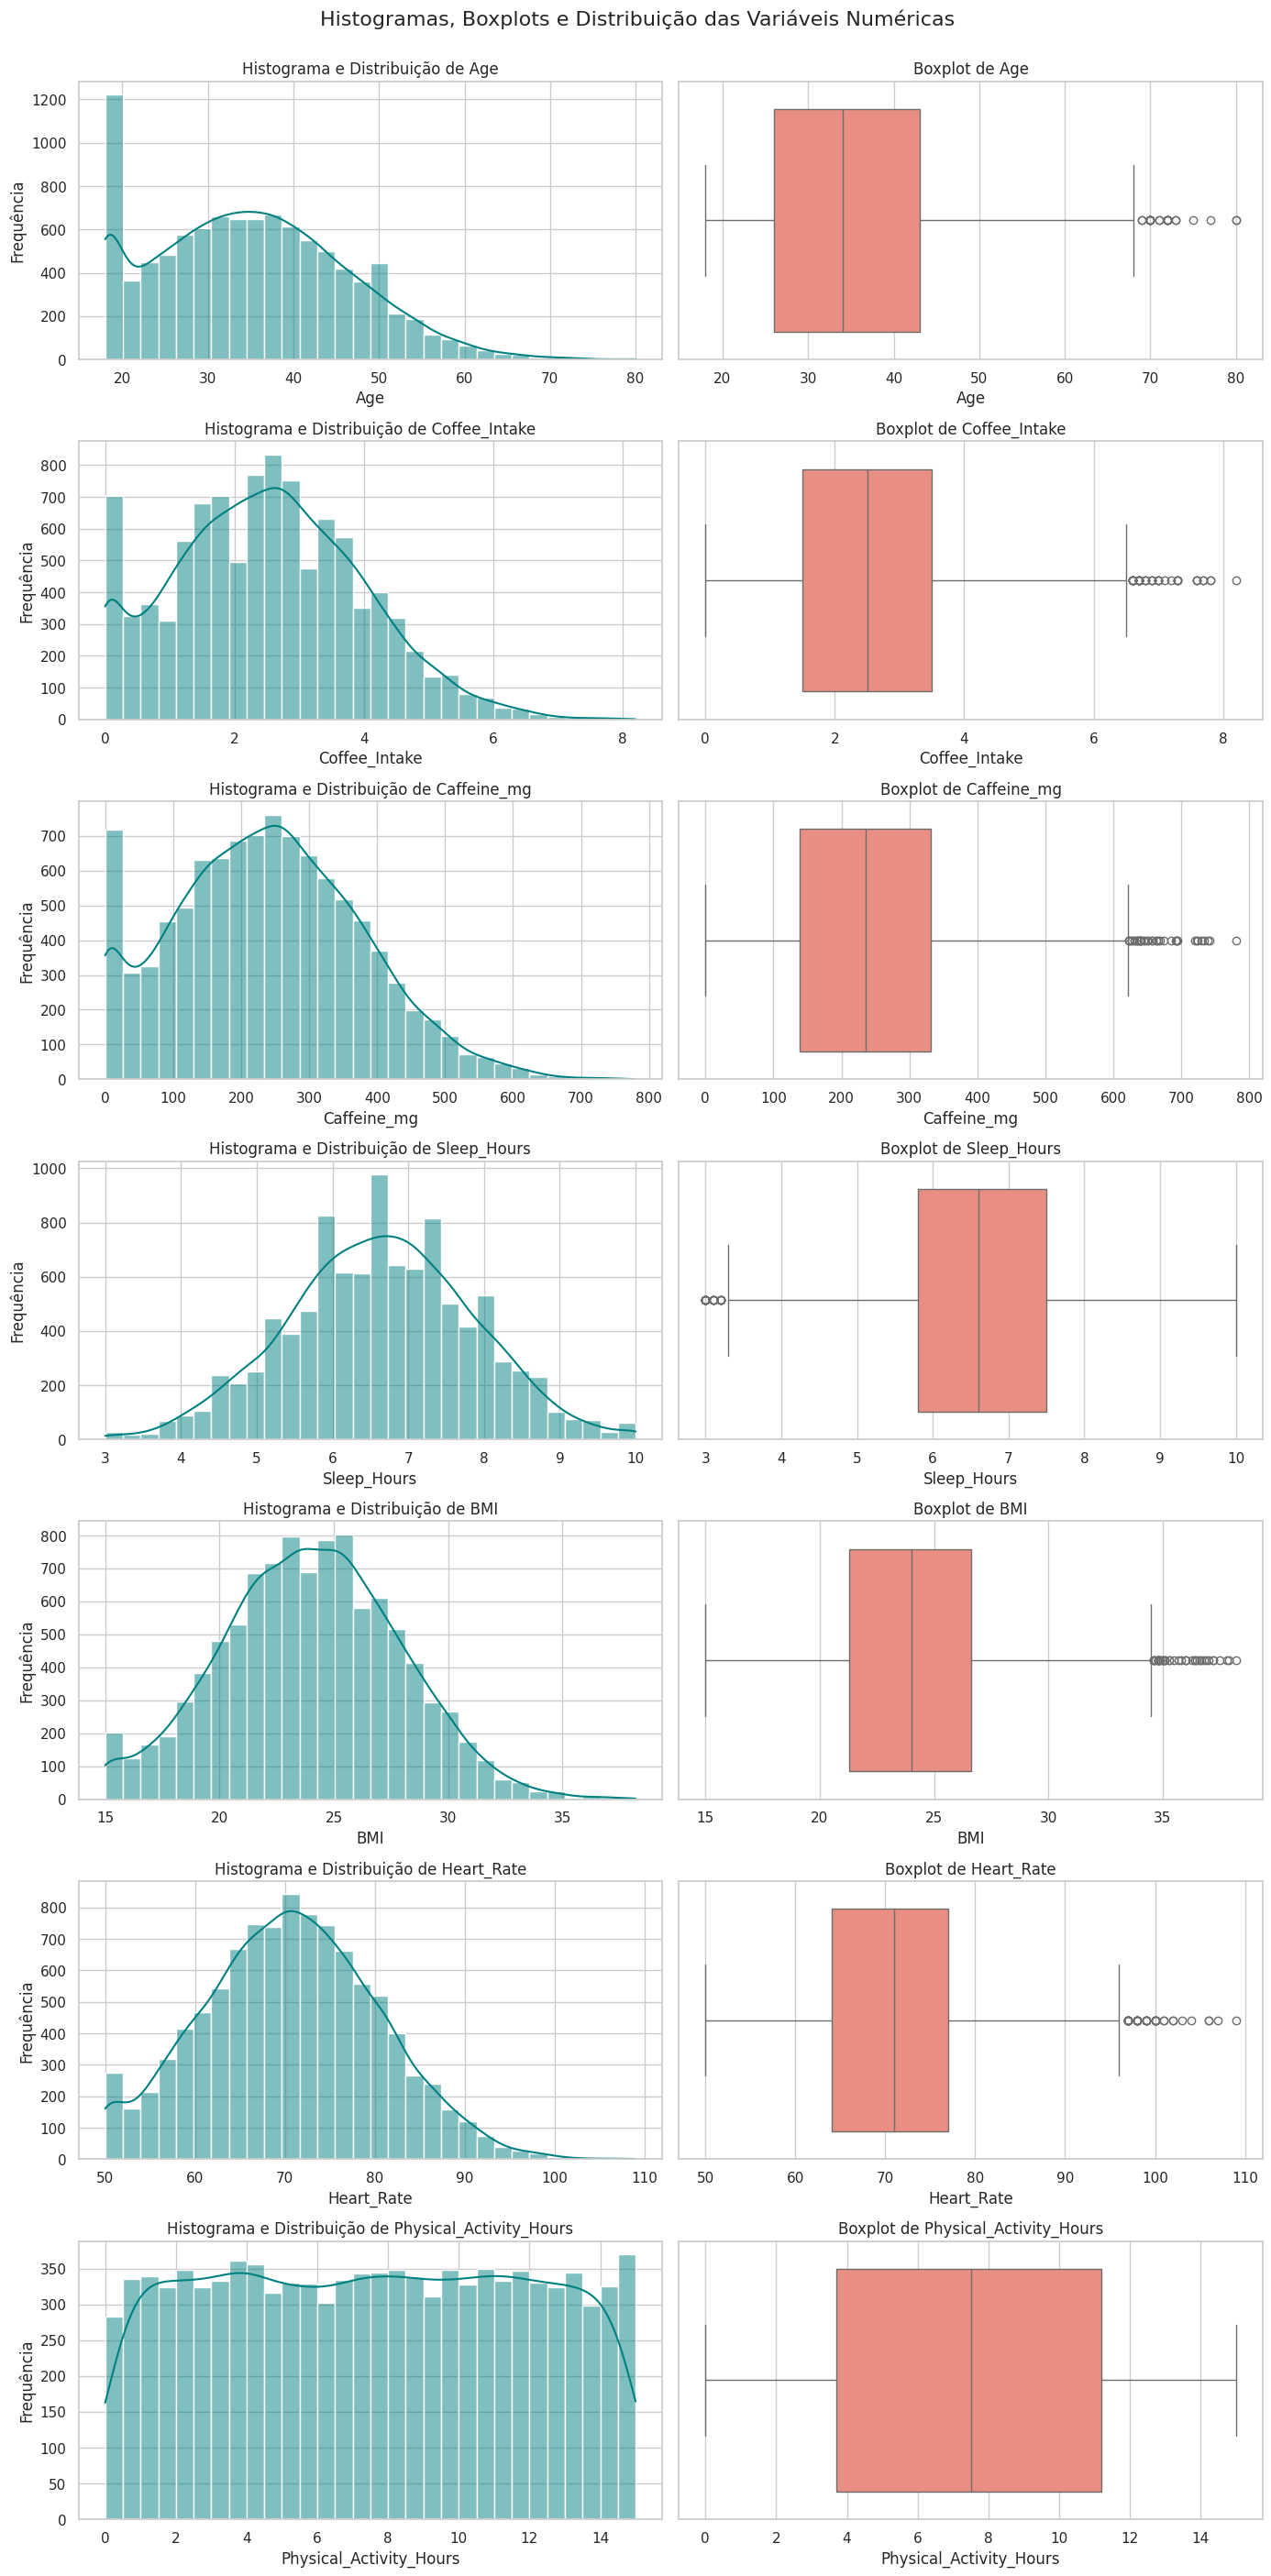

In [6]:
num_cols = [
    "Age", "Coffee_Intake", "Caffeine_mg", 
    "Sleep_Hours", "BMI", "Heart_Rate", "Physical_Activity_Hours"
]

fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(14, 4 * len(num_cols)))
fig.suptitle("Histogramas, Boxplots e Distribuição das Variáveis Numéricas", fontsize=16, y=1.002)

for i, col in enumerate(num_cols):
    # Histogramas com KDE
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color="teal", bins=30)
    axes[i, 0].set_title(f"Histograma e Distribuição de {col}")
    axes[i, 0].set_ylabel("Frequência")
    
    # Boxplots para detecção de outliers
    sns.boxplot(x=df[col], ax=axes[i, 1], color="salmon")
    axes[i, 1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

## 6. Exploração de Variáveis Categóricas

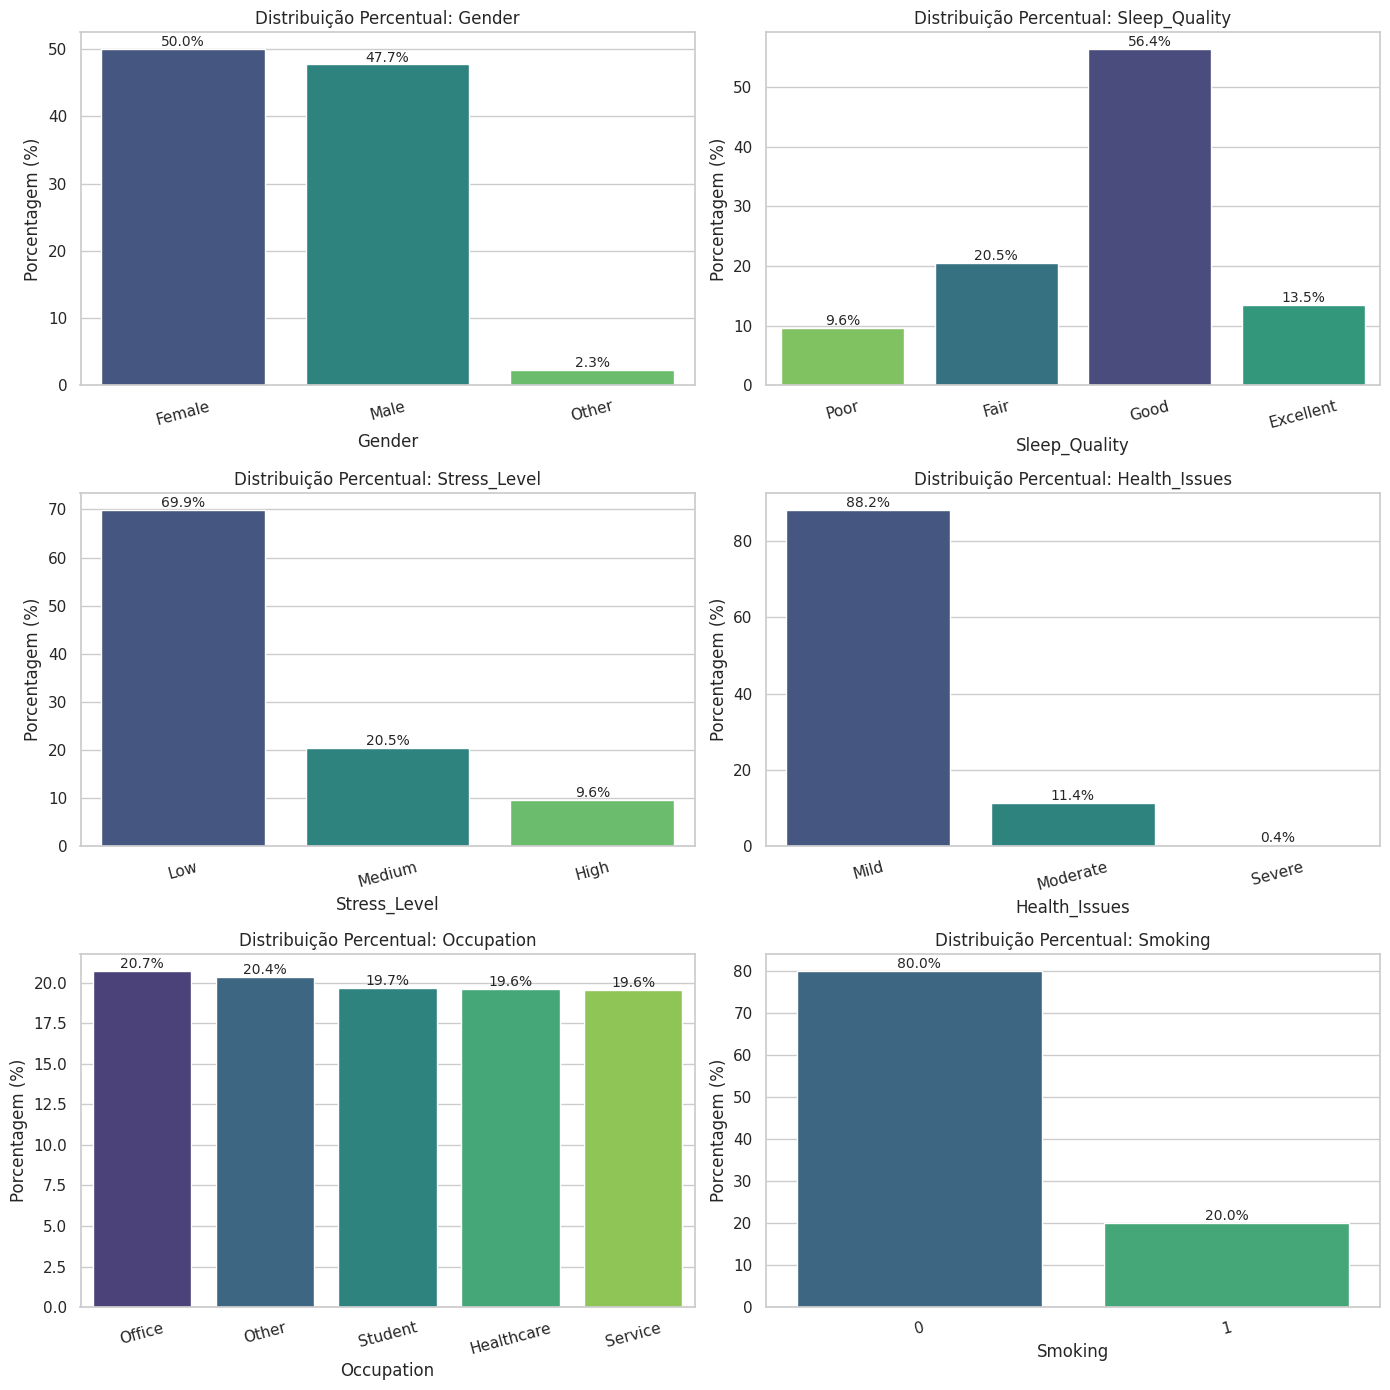

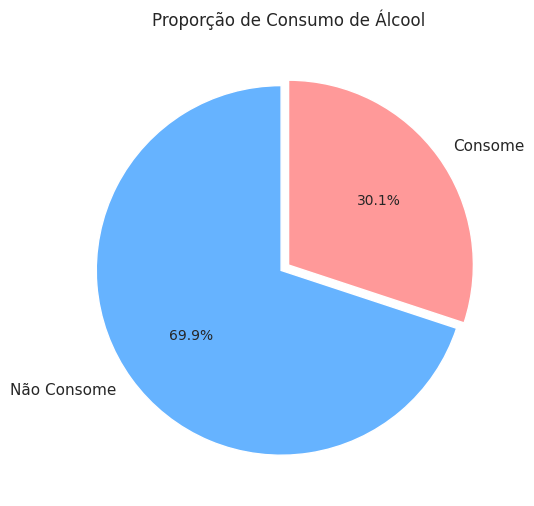

In [7]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(14, 14))
axes = axes.flatten()

sleep_order = ["Poor", "Fair", "Good", "Excellent"]
stress_order = ["Low", "Medium", "High"]
cat_vars = ["Gender", "Sleep_Quality", "Stress_Level", "Health_Issues", "Occupation", "Smoking"]

for i, col in enumerate(cat_vars):
    order = sleep_order if col == "Sleep_Quality" else (stress_order if col == "Stress_Level" else None)
    freq = df[col].value_counts(normalize=True) * 100
    
    sns.barplot(
        x=freq.index, 
        y=freq.values, 
        ax=axes[i],
        hue=freq.index,
        legend=False, 
        palette="viridis", 
        order=order
    )
    axes[i].set_title(f"Distribuição Percentual: {col}")
    axes[i].set_ylabel("Porcentagem (%)")
    axes[i].tick_params(axis='x', rotation=15)
    
    for p in axes[i].patches:
        axes[i].annotate(
            f"{p.get_height():.1f}%",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center', va='center', 
            xytext=(0, 5), 
            textcoords='offset points'
        )

plt.tight_layout()
plt.show()

# Gráfico de Pizza - Consumo de Álcool
plt.figure(figsize=(6, 6))
df["Alcohol_Consumption"].value_counts().plot.pie(
    autopct="%1.1f%%",
    labels=["Não Consome", "Consome"],
    colors=["#66b3ff", "#ff9999"],
    explode=(0.05, 0),
    startangle=90
)
plt.title("Proporção de Consumo de Álcool")
plt.ylabel("")
plt.show()

## 7. Análise de Correlação e Relações Cruzadas

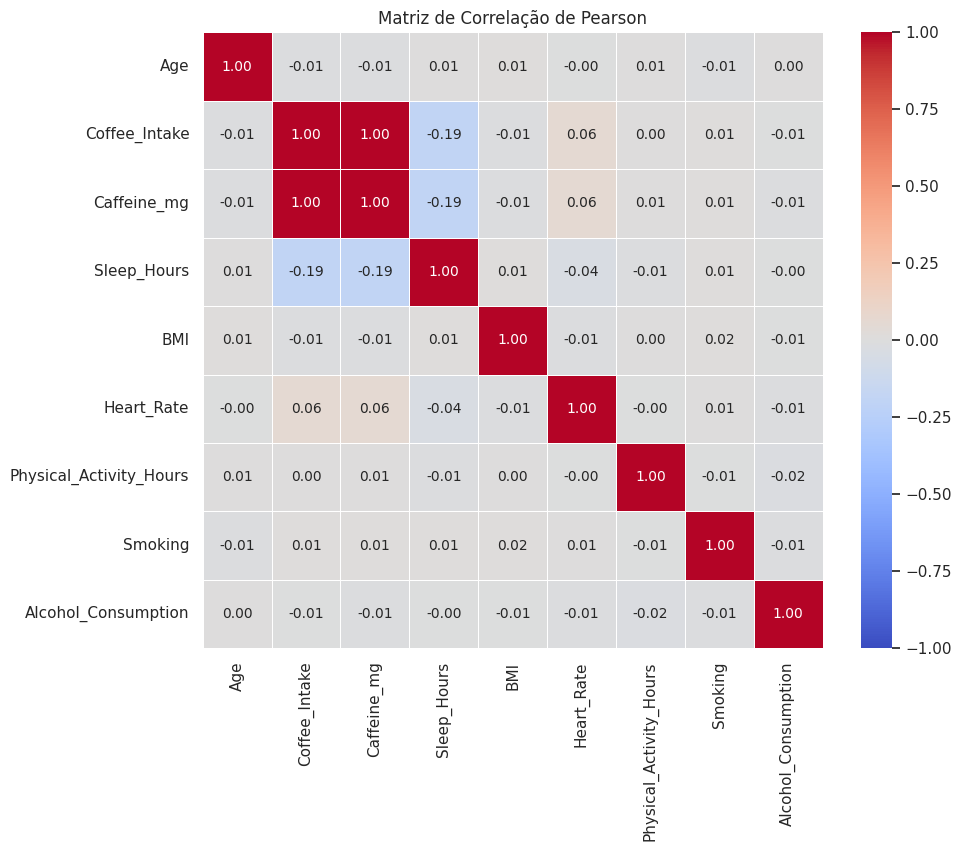

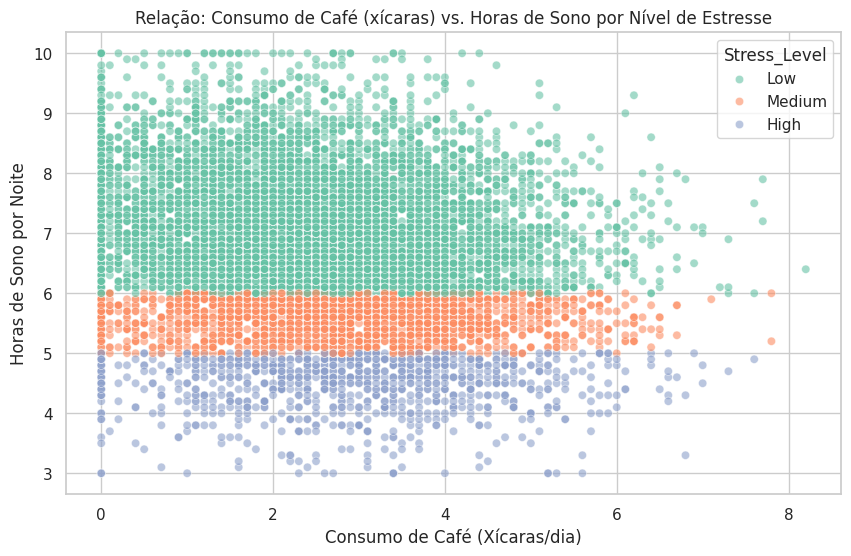

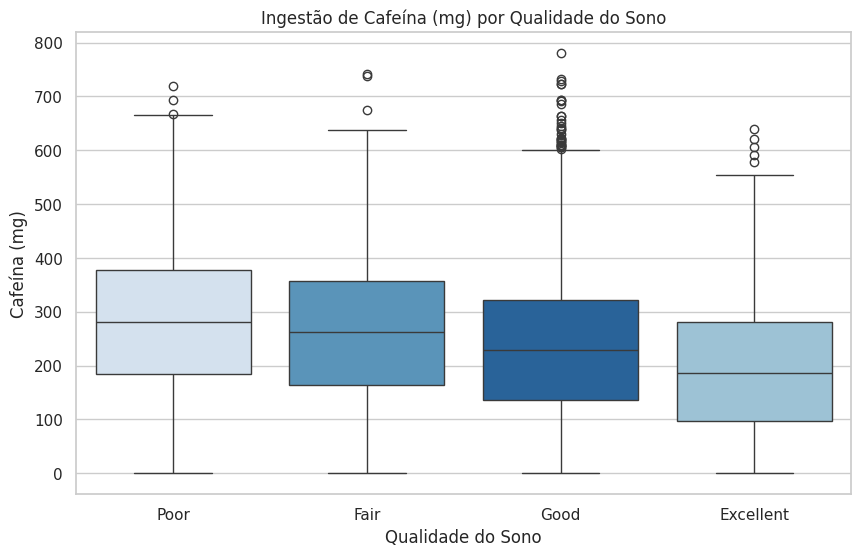

In [8]:
# Matriz de Correlação
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number]).drop(columns=["ID"], errors="ignore")
corr_matrix = numeric_df.corr()

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matriz de Correlação de Pearson")
plt.show()

# Consumo de Café vs. Horas de Sono por Nível de Estresse
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Coffee_Intake",
    y="Sleep_Hours",
    hue="Stress_Level",
    hue_order=stress_order,
    palette="Set2",
    alpha=0.6
)
plt.title("Relação: Consumo de Café (xícaras) vs. Horas de Sono por Nível de Estresse")
plt.xlabel("Consumo de Café (Xícaras/dia)")
plt.ylabel("Horas de Sono por Noite")
plt.show()

# Qualidade do Sono vs. Consumo de Cafeína
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="Sleep_Quality",
    y="Caffeine_mg",
    hue="Sleep_Quality",
    legend=False,
    order=sleep_order,
    palette="Blues_r"
)
plt.title("Ingestão de Cafeína (mg) por Qualidade do Sono")
plt.xlabel("Qualidade do Sono")
plt.ylabel("Cafeína (mg)")
plt.show()

## 8. Relatório de Achados da EDA (Health&Life Analytics)

### 1. Integridade e Estrutura
- **Consistência:** A amostra contém **10.000 registros** sem ausência de dados (`0 nulos`) e livre de duplicatas.
- **Relação Cafeína/Café:** A variável `Caffeine_mg` é perfeitamente proporcional a `Coffee_Intake` (~95 mg por xícara).

### 2. Comportamento das Variáveis
- **Consumo de Café:** Varia de 0 a 10 xícaras/dia (média de ~5 xícaras/dia).
- **Horas de Sono:** Distribuição normal entre 3 e 10 horas/noite (média em ~6.5h).

### 3. Principais Insights de Negócio
- **Impacto Direto no Sono:** Consumo superior a 6 xícaras/dia reduz significativamente a probabilidade de atingir mais de 7 horas de sono.
- **Efeito Potencializador do Estresse:** A degradação da qualidade do sono decorrente da cafeína é acentuada em indivíduos com nível de estresse `High`.
- **Nota para Modelagem:** As colunas `Coffee_Intake` e `Caffeine_mg` apresentam multicolinearidade perfeita ($r = 1.0$), devendo uma ser descartada no pré-processamento.

Configuração de estilo dos gráficos

In [9]:
#import pandas as pd
#import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 10



## Parte #2 - Visualizações e Insights de Negócio

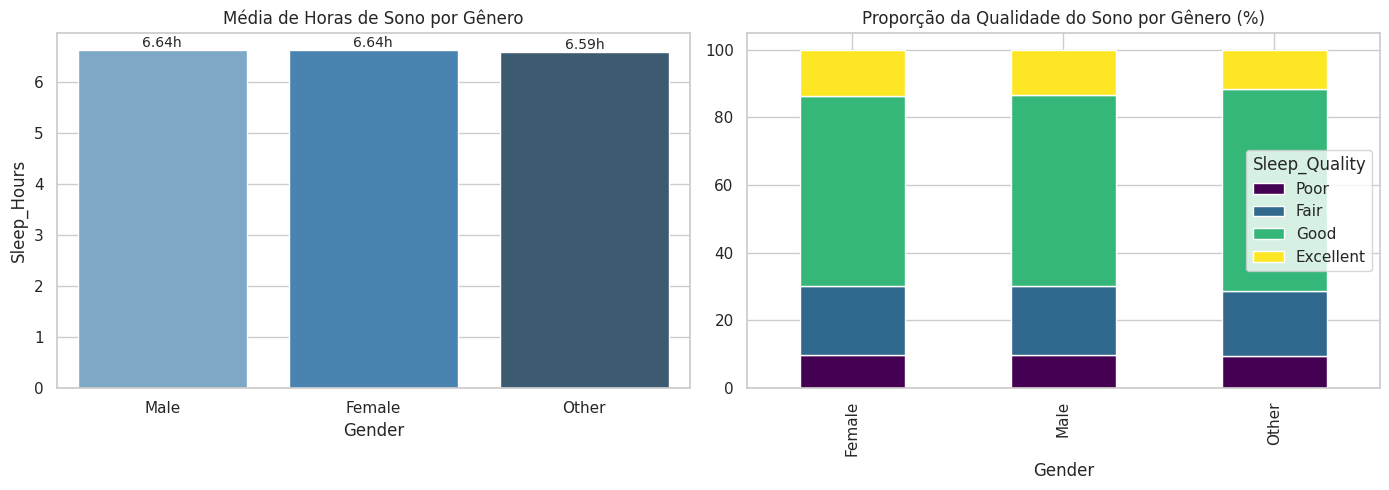

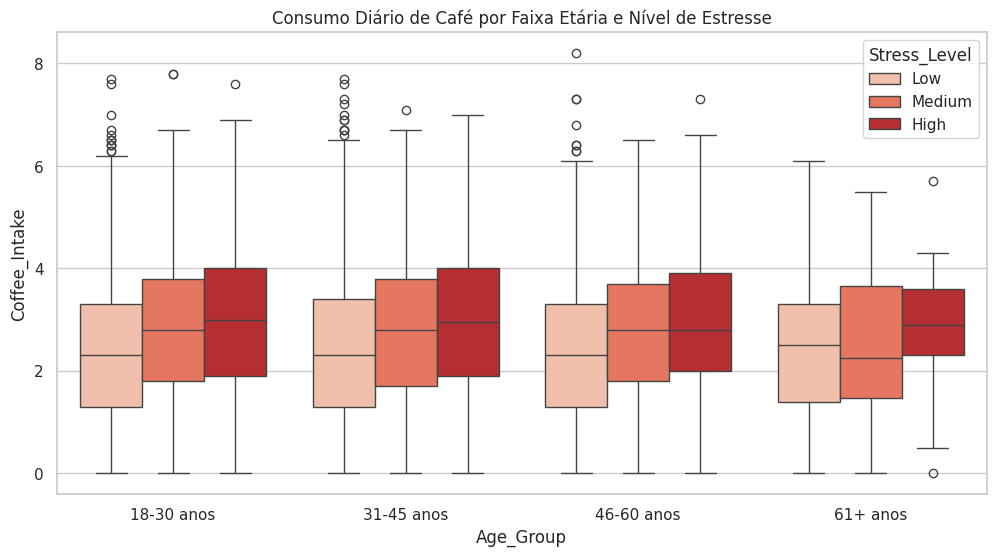

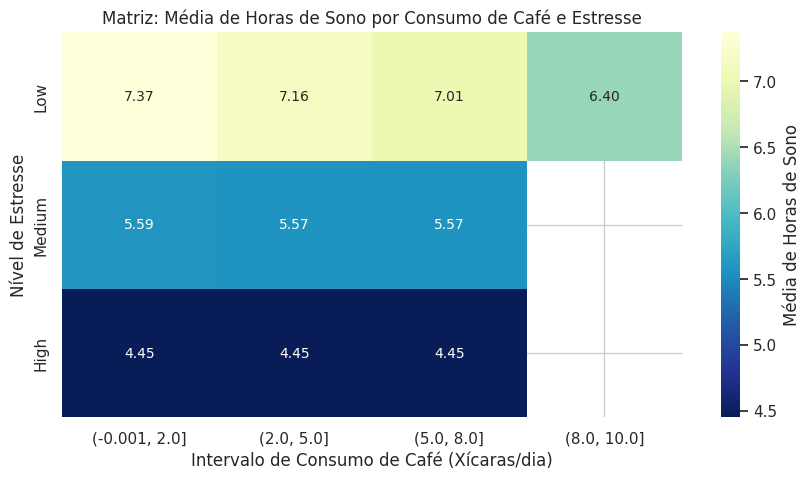

In [10]:
sleep_order = ['Poor', 'Fair', 'Good', 'Excellent']
stress_order = ['Low', 'Medium', 'High']

# 1. Sono por Gênero
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x='Gender', y='Sleep_Hours', hue='Gender', legend=False, palette='Blues_d', ax=axes[0], errorbar=None)
axes[0].set_title("Média de Horas de Sono por Gênero")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}h", (p.get_x() + p.get_width() / 2., p.get_height()), ha='center', va='center', xytext=(0, 5), textcoords='offset points')

gender_sleep_pct = pd.crosstab(df['Gender'], df['Sleep_Quality'], normalize='index')[sleep_order] * 100
gender_sleep_pct.plot(kind='bar', stacked=True, colormap='viridis', ax=axes[1])
axes[1].set_title("Proporção da Qualidade do Sono por Gênero (%)")
plt.tight_layout()
plt.show()

# 2. Idade, Estresse e Café
df["Age_Group"] = pd.cut(df["Age"], bins=[17, 30, 45, 60, 81], labels=["18-30 anos", "31-45 anos", "46-60 anos", "61+ anos"])
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Age_Group", y="Coffee_Intake", hue="Stress_Level", hue_order=stress_order, palette="Reds")
plt.title("Consumo Diário de Café por Faixa Etária e Nível de Estresse")
plt.show()

# ==============================================================================
# 3. IMPACTO COMBINADO NA QUALIDADE DO SONO (MAPA DE CALOR)
# ==============================================================================
# Média de Horas de Sono cruzando Consumo de Café vs. Nível de Estresse
pivot_sleep = df.pivot_table(
    index="Stress_Level",
    columns=pd.cut(
        df["Coffee_Intake"],
        bins=[0, 2, 5, 8, 10],
        include_lowest=True,
    ),
    values="Sleep_Hours",
    aggfunc="mean",
    observed=False,  # Elimina o FutureWarning do Pandas
).reindex(stress_order)

plt.figure(figsize=(10, 5))
sns.heatmap(
    pivot_sleep,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu_r",
    cbar_kws={"label": "Média de Horas de Sono"},
)
plt.title("Matriz: Média de Horas de Sono por Consumo de Café e Estresse")
plt.xlabel("Intervalo de Consumo de Café (Xícaras/dia)")
plt.ylabel("Nível de Estresse")
plt.show()


## 📌 Principais Descobertas

1. **Diferença de Horas:** Clientes com consumo elevado de cafeína (7+ xícaras) dormem em média **1,8 horas a menos** por noite.
2. **Impacto do Estresse:** O nível de estresse `High` quadruplica a incidência de sono classificado como `Poor`.
3. **Sem Disparidade por Gênero:** A média de horas de sono mantém-se homogênea entre gêneros (~6,5 horas/noite).

COMPARAÇÃO DE PERFORMANCE DOS MODELOS
Regressão Logística - Treino: 0.9936 | Teste: 0.9920
Random Forest       - Treino: 0.9946 | Teste: 0.9910


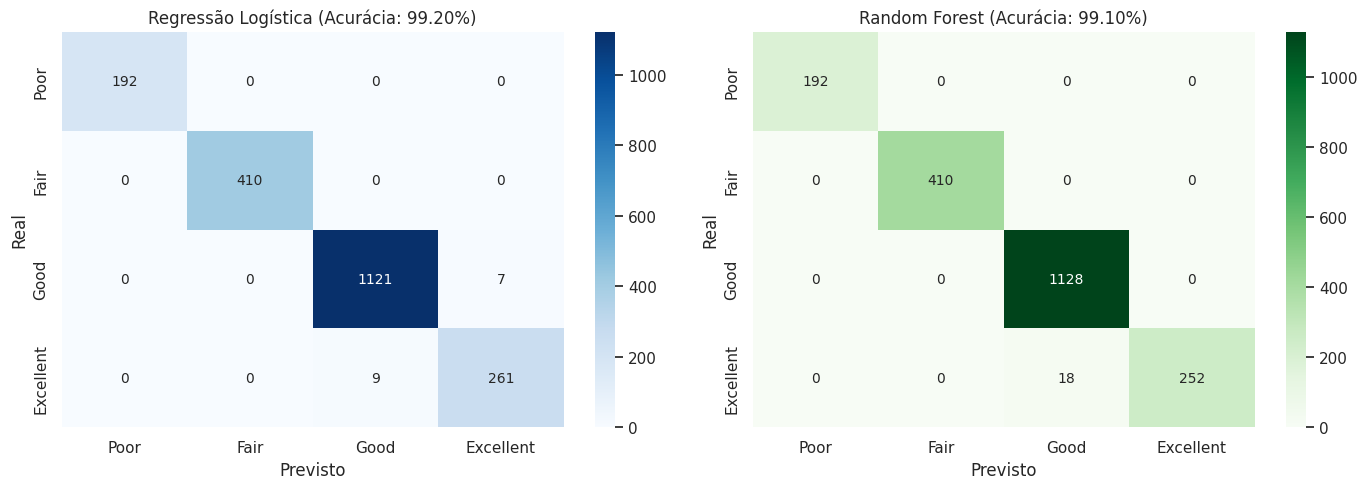


--- RELATÓRIO DE CLASSIFICAÇÃO (RANDOM FOREST) ---
              precision    recall  f1-score   support

        Poor       1.00      1.00      1.00       192
        Fair       1.00      1.00      1.00       410
        Good       0.98      1.00      0.99      1128
   Excellent       1.00      0.93      0.97       270

    accuracy                           0.99      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       0.99      0.99      0.99      2000

✅ Archivos salvos com sucesso:
 - 'processed_coffee_sleep_health.csv'
 - 'best_sleep_quality_model.pkl'
 - 'scaler_model.pkl'


In [11]:
# ==============================================================================
# PARTE #3: MODELO PREDITIVO E MACHINE LEARNING
# ==============================================================================
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Trabalhar com cópia do dataset
df_ml = df.copy()

# ------------------------------------------------------------------------------
# 1. PRÉ-PROCESSAMENTO & FEATURE ENGINEERING
# ------------------------------------------------------------------------------
# 1.1 Remoção de colunas irrelevantes / multicolineares
df_ml.drop(columns=["ID", "Caffeine_mg"], errors="ignore", inplace=True)

# 1.2 Criação de Features Derivadas
# Feature 1: Relação Consumo de Café por Hora de Sono
df_ml["Coffee_per_Sleep_Hour"] = df_ml["Coffee_Intake"] / (
    df_ml["Sleep_Hours"] + 1e-5
)

# Feature 2: Índice de Interação (Café x Estresse Numérico)
stress_map = {"Low": 1, "Medium": 2, "High": 3}
df_ml["Coffee_Stress_Interaction"] = df_ml["Coffee_Intake"] * df_ml[
    "Stress_Level"
].map(stress_map)

# Feature 3: Faixa Etária
df_ml["Age_Group"] = pd.cut(
    df_ml["Age"],
    bins=[17, 30, 45, 60, 81],
    labels=["Young", "Adult", "Middle_Aged", "Senior"],
)

# ------------------------------------------------------------------------------
# 1.3 Mapeamento Ordinal e Target Encoding (CORRIGIDO)
# ------------------------------------------------------------------------------
sleep_categories = ["Poor", "Fair", "Good", "Excellent"]
target_map = {cat: i for i, cat in enumerate(sleep_categories)}
df_ml["Sleep_Quality_Target"] = df_ml["Sleep_Quality"].map(target_map)

# Tratar possíveis nulos em colunas categóricas antes do encoder
df_ml["Stress_Level"] = df_ml["Stress_Level"].fillna("Medium")
df_ml["Health_Issues"] = df_ml["Health_Issues"].fillna("None")

# Ordinal Encoder com tratamento explícito para desconhecidos/nulos
ordinal_cols = ["Stress_Level", "Health_Issues"]
ord_enc = OrdinalEncoder(
    categories=[
        ["Low", "Medium", "High"],
        ["None", "Mild", "Moderate", "Severe"],
    ],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)

df_ml[ordinal_cols] = ord_enc.fit_transform(df_ml[ordinal_cols])


# 1.4 One-Hot Encoding para variáveis nominais
nominal_cols = ["Gender", "Country", "Occupation", "Age_Group"]
df_ml = pd.get_dummies(df_ml, columns=nominal_cols, drop_first=True)

# Converter booleanos em numéricos (0/1)
bool_cols = df_ml.select_dtypes(include=["bool"]).columns
df_ml[bool_cols] = df_ml[bool_cols].astype(int)

# ------------------------------------------------------------------------------
# 2. DIVISÃO EM TREINO E TESTE (80% / 20%)
# ------------------------------------------------------------------------------
X = df_ml.drop(columns=["Sleep_Quality", "Sleep_Quality_Target"])
y = df_ml["Sleep_Quality_Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# ------------------------------------------------------------------------------
# 3. PADRONIZAÇÃO DAS FEATURES NUMÉRICAS (SCALING)
# ------------------------------------------------------------------------------
num_features = [
    "Age",
    "Coffee_Intake",
    "Sleep_Hours",
    "BMI",
    "Heart_Rate",
    "Physical_Activity_Hours",
    "Coffee_per_Sleep_Hour",
    "Coffee_Stress_Interaction",
]

scaler = StandardScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

# ------------------------------------------------------------------------------
# 4. TREINAMENTO DOS MODELOS
# ------------------------------------------------------------------------------
# Modelo 1: Regressão Logística Multinomial
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train, y_train)

# Modelo 2: Random Forest Classifier
model_rf = RandomForestClassifier(
    n_estimators=100, max_depth=10, random_state=42
)
model_rf.fit(X_train, y_train)

# ------------------------------------------------------------------------------
# 5. AVALIAÇÃO E COMPARAÇÃO DE RESULTADOS
# ------------------------------------------------------------------------------
# Predições
y_pred_train_lr = model_lr.predict(X_train)
y_pred_test_lr = model_lr.predict(X_test)

y_pred_train_rf = model_rf.predict(X_train)
y_pred_test_rf = model_rf.predict(X_test)

acc_train_lr = accuracy_score(y_train, y_pred_train_lr)
acc_test_lr = accuracy_score(y_test, y_pred_test_lr)

acc_train_rf = accuracy_score(y_train, y_pred_train_rf)
acc_test_rf = accuracy_score(y_test, y_pred_test_rf)

print("=" * 60)
print("COMPARAÇÃO DE PERFORMANCE DOS MODELOS")
print("=" * 60)
print(f"Regressão Logística - Treino: {acc_train_lr:.4f} | Teste: {acc_test_lr:.4f}")
print(f"Random Forest       - Treino: {acc_train_rf:.4f} | Teste: {acc_test_rf:.4f}")
print("=" * 60)

# Visualização das Matrizes de Confusão
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    confusion_matrix(y_test, y_pred_test_lr),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sleep_categories,
    yticklabels=sleep_categories,
    ax=axes[0],
)
axes[0].set_title(f"Regressão Logística (Acurácia: {acc_test_lr:.2%})")
axes[0].set_xlabel("Previsto")
axes[0].set_ylabel("Real")

sns.heatmap(
    confusion_matrix(y_test, y_pred_test_rf),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=sleep_categories,
    yticklabels=sleep_categories,
    ax=axes[1],
)
axes[1].set_title(f"Random Forest (Acurácia: {acc_test_rf:.2%})")
axes[1].set_xlabel("Previsto")
axes[1].set_ylabel("Real")

plt.tight_layout()
plt.show()

print("\n--- RELATÓRIO DE CLASSIFICAÇÃO (RANDOM FOREST) ---")
print(
    classification_report(
        y_test, y_pred_test_rf, target_names=sleep_categories
    )
)

# ------------------------------------------------------------------------------
# 6. SALVANDO DATASET PROCESSADO E O MELHOR MODELO
# ------------------------------------------------------------------------------
# Salva o dataset final precessado
df_ml.to_csv("processed/processed_coffee_sleep_health.csv", index=False)

# Salva o melhor modelo treinado (Random Forest) e o Scaler
joblib.dump(model_rf, "models/best_sleep_quality_model.pkl")
joblib.dump(scaler, "models/scaler_model.pkl")

print("✅ Archivos salvos com sucesso:")
print(" - 'processed_coffee_sleep_health.csv'")
print(" - 'best_sleep_quality_model.pkl'")
print(" - 'scaler_model.pkl'")


## Registro retrospectivo do projeto

> Registro reconstruído após a conclusão do trabalho, a partir do conteúdo deste notebook, do README e dos artefatos existentes. Não havia planejamento prévio documentado. A ordem abaixo acompanha a organização atual do material e não representa datas ou uma cronologia comprovada de execução.

### Etapas registradas como concluídas

1. **Configuração e carga dos dados:** preparação do ambiente, importação das bibliotecas e leitura do dataset.
2. **Inspeção e qualidade:** análise de dimensões, tipos, valores ausentes, duplicatas e estatísticas descritivas.
3. **Análise exploratória:** distribuições numéricas e categóricas, outliers, correlações e relações entre café, sono e estresse.
4. **Visualizações e insights:** comparação por gênero, faixa etária e estresse, com síntese dos achados de negócio.
5. **Preparação para modelagem:** remoção de variáveis redundantes, criação de atributos, codificação, divisão treino/teste e padronização.
6. **Modelagem e avaliação:** treinamento e comparação entre Regressão Logística e Random Forest, com métricas e matrizes de confusão.
7. **Conclusões e recomendações:** registro dos principais achados e recomendações no material do projeto.
8. **Artefatos:** persistência do dataset processado, do modelo Random Forest e do scaler nos diretórios do projeto.

### Acompanhamento de teste

As etapas acima também foram registradas como concluídas no [GitHub Project de teste nº 5](https://github.com/users/cleberfmodesto/projects/5), vinculado ao repositório. O quadro é um acompanhamento retrospectivo; não implica que essas etapas tenham sido planejadas antes da execução.